# Tutorial: Self-attention from scratch

The recurrent network in `tf.keras_rnn.ipynb` reads a sequence one element at a time and carries what it has seen forward in its internal state. A **Transformer** works differently: every element of the sequence looks at every other element directly, in a single step, through a mechanism called **attention**.

In this tutorial we build self-attention by hand using only NumPy, the same way `perceptron.ipynb` and `mlp_bp_ann.ipynb` build their networks without a neural network library. Nothing is trained here. The goal is to see exactly which numbers flow through an attention layer. The next two tutorials train Transformers with TensorFlow Keras.

# Background - Queries, keys and values

Each element of the sequence (a **token**, here a word) is turned into three vectors:

* a **query**: what am I looking for?
* a **key**: what do I contain?
* a **value**: what do I pass on to the tokens that attend to me?

A token compares its query with the key of every token: a good match gives a high score. The scores are turned into weights that add up to 1 with a softmax, and the token's output is the weighted average of all the values. Written as one formula, from the paper that introduced the Transformer ([Vaswani et al., 2017, *Attention Is All You Need*](https://arxiv.org/abs/1706.03762)):

$$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V$$

where $Q$, $K$ and $V$ hold one query, key and value per row, and $d_k$ is the length of the query and key vectors.

# Step 0 - Setup the learning environment

To begin, we import the library modules that we will use.

Numpy is a collection of math functions including various matrix operations - see http://www.numpy.org/. Matplotlib is a 2D plotting library - see https://matplotlib.org/.

In [1]:
"""
attention_numpy.py

Self-attention tutorial using Numpy only, without the aid of additional NN libraries.
Builds scaled dot-product attention, a causal mask and multi-head attention
step by step for a six-word sentence, and plots the attention weights.
"""

import numpy as np
import matplotlib.pyplot as plt

# Set the seed value of the random number generator
random_seed = 2
np.random.seed(random_seed)

np.set_printoptions(precision=2, suppress=True)   # print matrices with 2 decimals

print("The environment is ready.")

The environment is ready.


# Step 1 - Create the input data

Our sequence is a sentence of six words. In a real model every word is first turned into a vector of numbers called an **embedding**, which is learned during training. Here we use random vectors of length 8 (`d_model`).

Attention on its own has no idea of word order. So Transformers add a **positional encoding** to each embedding: a fixed pattern of sine and cosine waves that is different for every position. The two "the"s start with identical embeddings, and the positional encoding is what tells them apart.

Input shape (seq_len, d_model): (6, 8)
The two 'the' embeddings are identical: True
After adding positions they differ:     True


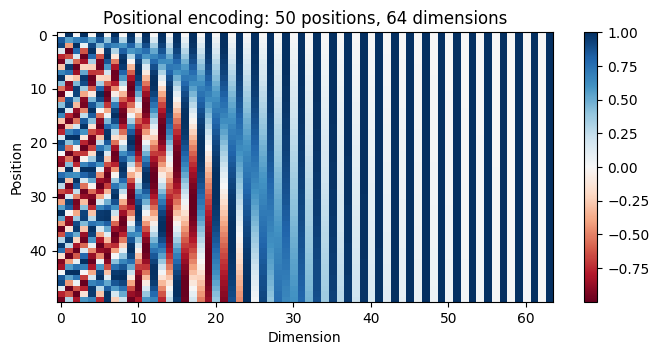

In [2]:
tokens = ["the", "cat", "sat", "on", "the", "mat"]
seq_len = len(tokens)
d_model = 8          # length of each word vector

# One random embedding per distinct word, so both "the"s get the same vector
vocab = sorted(set(tokens))
embedding_table = np.random.randn(len(vocab), d_model)
embeddings = np.array([embedding_table[vocab.index(t)] for t in tokens])   # (seq_len, d_model)


def positional_encoding(length, depth):
    """Sine and cosine waves of different speeds, one row per position (from the Transformer paper)."""
    position = np.arange(length)[:, np.newaxis]                              # (length, 1)
    div_term = np.exp(np.arange(0, depth, 2) * (-np.log(10000.0) / depth))   # one speed per pair of columns
    pe = np.zeros((length, depth))
    pe[:, 0::2] = np.sin(position * div_term)    # even columns
    pe[:, 1::2] = np.cos(position * div_term)    # odd columns
    return pe


x = embeddings + positional_encoding(seq_len, d_model)    # the input to the attention layer

print("Input shape (seq_len, d_model):", x.shape)
print("The two 'the' embeddings are identical:", np.allclose(embeddings[0], embeddings[4]))
print("After adding positions they differ:    ", not np.allclose(x[0], x[4]))

# Plot the positional encoding for a longer sequence to see the wave pattern
plt.figure(1, figsize=(8, 3.5))
plt.imshow(positional_encoding(50, 64), cmap="RdBu", aspect="auto")
plt.xlabel("Dimension")
plt.ylabel("Position")
plt.title("Positional encoding: 50 positions, 64 dimensions")
plt.colorbar()
plt.show()

# Step 2 - Configure the attention layer

An attention layer has three weight matrices, $W_Q$, $W_K$ and $W_V$, which turn each input vector into its query, key and value. In a trained network these weights are learned by backpropagation, just like the weights in `mlp_bp_ann.ipynb`. Here they are initialized randomly, so the attention pattern we get will be arbitrary. Training is what makes it meaningful.

In [3]:
d_k = 4     # length of each query, key and value vector

# Initialize the weights of the layer with small random values
W_q = np.random.randn(d_model, d_k) * 0.5
W_k = np.random.randn(d_model, d_k) * 0.5
W_v = np.random.randn(d_model, d_k) * 0.5

print("W_q, W_k and W_v shapes:", W_q.shape, W_k.shape, W_v.shape)

W_q, W_k and W_v shapes: (8, 4) (8, 4) (8, 4)


# Step 3 - Compute the attention

Now we follow the formula one piece at a time: the queries, keys and values; the scores; the softmax; and the weighted sum of the values.

In [4]:
# Queries, keys and values: one row per word
Q = x @ W_q     # (seq_len, d_k)
K = x @ W_k     # (seq_len, d_k)
V = x @ W_v     # (seq_len, d_k)

# Scores: how well each word's query matches each word's key, divided by sqrt(d_k)
scores = Q @ K.T / np.sqrt(d_k)     # (seq_len, seq_len)


def softmax(z):
    """Softmax along the last axis. Subtracting the largest value first avoids overflow."""
    e = np.exp(z - z.max(axis=-1, keepdims=True))
    return e / e.sum(axis=-1, keepdims=True)


# Attention weights: each row becomes a set of weights that add up to 1
weights = softmax(scores)           # (seq_len, seq_len)

# Output: each word's new vector is a weighted average of all the value vectors
output = weights @ V                # (seq_len, d_k)

print("Scores:\n", scores)
print("\nAttention weights:\n", weights)
print("\nEach row sums to 1:", weights.sum(axis=1))
print("\nOutput shape:", output.shape)

Scores:
 [[ 3.9   1.66 -4.95 -0.4   4.47  5.97]
 [-2.6  -1.58  5.66  0.39  0.43  1.05]
 [-5.25 -3.9   9.39  0.31 -1.76 -3.03]
 [-0.79 -0.48  1.65  0.16  0.14  0.62]
 [ 5.2   2.62 -8.37 -0.45  3.76  5.72]
 [ 4.39  2.34 -8.05 -0.24  2.27  4.66]]

Attention weights:
 [[0.09 0.01 0.   0.   0.16 0.73]
 [0.   0.   0.98 0.01 0.01 0.01]
 [0.   0.   1.   0.   0.   0.  ]
 [0.04 0.06 0.5  0.11 0.11 0.18]
 [0.33 0.03 0.   0.   0.08 0.56]
 [0.39 0.05 0.   0.   0.05 0.51]]

Each row sums to 1: [1. 1. 1. 1. 1. 1.]

Output shape: (6, 4)


### Why divide by $\sqrt{d_k}$?

The scores are dot products of $d_k$ numbers, so they get bigger as $d_k$ grows. Big scores make the softmax put almost all the weight on a single word, and then the gradients that training relies on become tiny. Dividing by $\sqrt{d_k}$ keeps the scores in the same range whatever $d_k$ is. Compare the largest weight a query gives to one of 10 random keys:

In [5]:
for dk in [4, 64, 512]:
    q = np.random.randn(dk)          # one query
    k = np.random.randn(10, dk)      # ten keys
    unscaled = softmax(k @ q)
    scaled = softmax(k @ q / np.sqrt(dk))
    print("d_k = %3d   largest weight without scaling: %.2f   with scaling: %.2f" % (dk, unscaled.max(), scaled.max()))

d_k =   4   largest weight without scaling: 0.58   with scaling: 0.31
d_k =  64   largest weight without scaling: 0.74   with scaling: 0.34
d_k = 512   largest weight without scaling: 1.00   with scaling: 0.32


# Step 4 - Evaluate: plot the attention weights and add a mask

Row *i* of the attention weights shows how much word *i* takes from each of the words. A heat map makes this easy to read.

When a decoder writes a sentence one word at a time, a word must not look at the words that come after it. A **causal mask** replaces those scores with a very large negative number before the softmax, so their weights become 0.

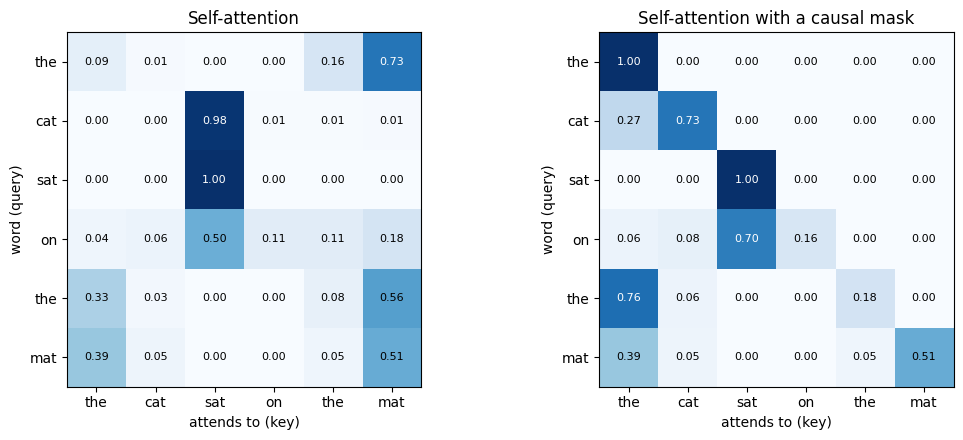

In [6]:
# Causal mask: True above the diagonal, i.e. the "future" words that must be hidden
causal_mask = np.triu(np.ones((seq_len, seq_len), dtype=bool), k=1)
masked_weights = softmax(np.where(causal_mask, -1e9, scores))


def plot_weights(ax, w, title):
    """Heat map of an attention matrix with the words on both axes and the values written in."""
    ax.imshow(w, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(seq_len))
    ax.set_xticklabels(tokens)
    ax.set_yticks(range(seq_len))
    ax.set_yticklabels(tokens)
    ax.set_xlabel("attends to (key)")
    ax.set_ylabel("word (query)")
    ax.set_title(title)
    for i in range(seq_len):
        for j in range(seq_len):
            ax.text(j, i, "%.2f" % w[i, j], ha="center", va="center", fontsize=8,
                    color="white" if w[i, j] > 0.6 else "black")


fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
plot_weights(axes[0], weights, "Self-attention")
plot_weights(axes[1], masked_weights, "Self-attention with a causal mask")
plt.tight_layout()
plt.show()

The pattern on the left has no meaning yet because the weights are random. On the right, everything above the diagonal is 0: "cat" can only see "the" and itself, while the last word can see the whole sentence. The decoder in `tf.keras_transformer_dates.ipynb` uses exactly this mask.

# Step 5 - Multi-head attention

One attention layer can only learn one way of mixing the words. **Multi-head attention** runs several smaller attention layers ("heads") side by side, each with its own $W_Q$, $W_K$ and $W_V$, so each head can learn to look for something different. The heads' outputs are joined back together and mixed by one more weight matrix, $W_O$.

This is the layer that Keras provides as `layers.MultiHeadAttention`, which the next two tutorials use.

One head's output: (6, 4)
Heads joined:      (6, 8)
After W_o:         (6, 8) - the same shape as the input x (6, 8)


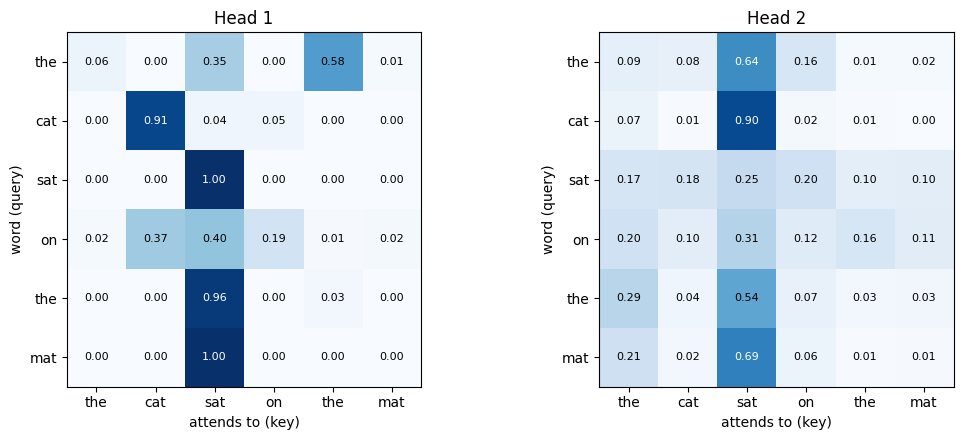

In [7]:
num_heads = 2
d_head = d_model // num_heads      # each head works with vectors of length 4


def attention(x, W_q, W_k, W_v, mask=None):
    """Scaled dot-product attention for one head. Returns the output and the attention weights."""
    Q, K, V = x @ W_q, x @ W_k, x @ W_v
    scores = Q @ K.T / np.sqrt(W_q.shape[1])
    if mask is not None:
        scores = np.where(mask, -1e9, scores)
    w = softmax(scores)
    return w @ V, w


head_outputs, head_weights = [], []
for h in range(num_heads):
    # every head has its own randomly initialized weights
    W_q_h = np.random.randn(d_model, d_head) * 0.5
    W_k_h = np.random.randn(d_model, d_head) * 0.5
    W_v_h = np.random.randn(d_model, d_head) * 0.5
    out, w = attention(x, W_q_h, W_k_h, W_v_h)
    head_outputs.append(out)
    head_weights.append(w)

# Join the heads side by side, then mix them with W_o
joined = np.concatenate(head_outputs, axis=-1)          # (seq_len, num_heads * d_head)
W_o = np.random.randn(num_heads * d_head, d_model) * 0.5
multi_head_output = joined @ W_o                         # (seq_len, d_model)

print("One head's output:", head_outputs[0].shape)
print("Heads joined:     ", joined.shape)
print("After W_o:        ", multi_head_output.shape, "- the same shape as the input x", x.shape)

fig, axes = plt.subplots(1, num_heads, figsize=(11, 4.5))
for h in range(num_heads):
    plot_weights(axes[h], head_weights[h], "Head %d" % (h + 1))
plt.tight_layout()
plt.show()

The output has the same shape as the input, so attention layers can be stacked one after another, and each head produced its own pattern from the same sentence.

**Things to try**

* In Step 3, remove `/ np.sqrt(d_k)` and run the cells again. The weights become more extreme.
* Change `d_k` or `num_heads`.
* In Step 1, use `x = embeddings` (no positional encoding) and run Steps 2 to 4 again. The rows for the two "the"s become identical, because without positions the layer can't tell them apart.